# 사전과제 : 딥러닝 2 Focus on transformer

# 1. 인트로
## 1. RNN의 한계와 attention의 등장
### attention의 등장
- seq2seq 복습 : 입력 시퀀스를 받아 다른 시퀀스로 변환하는 모델 구조
     - 장점 : 입력과 출력의 길이가 달라도 사용 가능, 다양한 변환 작업 (번역 요약 등)에 사용 가능
     - encoder : LSTM이 순차적으로 한 단어씩 읽고 문장 전체를 요약해서 압축된 하나의 벡터로 생성 ( i , study, math )
     - context vector: 인코더가 만든 문장의 요약본, 인코더랑 디코더를 잇는 유일 통로, encoder에 의한 하나의 결과물이자 decoder 입력으로 들어가는 고정된 크기의 벡터
     - decoder : context vector 를 받아서 번역문을 한 단어씩 만든다 (sos -> 나는 -> 수학을 -> 공부한다 -> eos), context vector 하나만 참고가 가능하다.
- attention의 등장 : 시퀀스 투 시퀀스 모델의 병목현상 
     -context vector 하나만 이용해서 출력 문장을 생성하기에 문장이 길어질수록 정보 손실 문제가 발생한다  <br> & 출력 단어마다 필요한 정보를 다르게 반영할 수 없다. <br> & context vector은 인코더의 마지막 은닉층으로 앞쪽 단어의 정보가 희미해진다.
     - 이러한 한계들을 해결하기 위해서 등장한 attention
- attention : 현재 시점에서 가장 중요한 부분에 더 높은 가중치를 부여하는 기술 <br>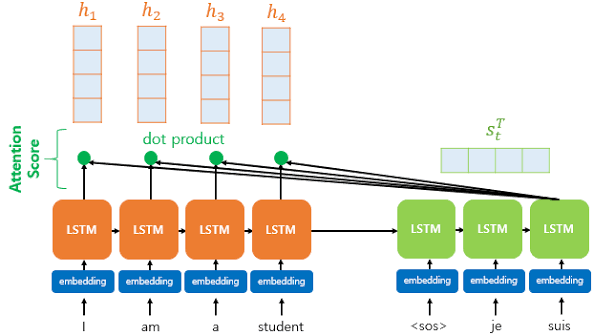 <br>
 - 디코더와 인코더의 **모든 위치를 직접 비교한다.** 
 - 각 단어와 관련도 점수로 서로를 기억하며 **동시에 비교 가능** -> **병렬화 가능성**
    - 단, 인코더와 디코더가 여전히 LSTM으로 한 칸씩 처리되기에 모델 전체의 병렬화는 아니다.-> RNN의 보조적 역할
    - -> LSTM을 걷어내고 어텐션만 남는 모델이 **Transformer** 모델이다.

- 어텐션의 과정
     - 1. 입력 -> 벡터 형태로 : 입력 단어를 컴퓨터가 읽을 수 있도록 숫자로 이루어진 벡터로 변환시킨다.
     - 2. 단어별 중요도를 계산 
          - 관련도 점수 (현재 작업과 각 단어 사이 관계가 얼마나 관련이 높고 유사한가),
          - softmax (관련도 점수를 0~1 사이의 확률 값으로 변환), 이 함수를 거친 비율을 어텐션 가중치라고 한다.
    - 3. 중요도에 따른 입력 정보 조합 : 어텐션 가중치만큼 각 단어의 hidden state 정보를 섞어 context vector를 만든다. 
         - 가장 **비율이 높은 단어 정보** 위주로 반영해서 다음 결과를 구성하게 된다.

- 어텐션의 장점
     - 1. 시간 경과에 대한 유연성 (<-> RNN- 장기의존성 문제)
          - 모든 단어를 직접 비교하므로 거리와 상관없이 관계 파악 가능
     - 2. 공간에 대한 유연성 ( <-> CNN - 고정된 필터로 주변 정보만 봄)
          - 모든 위치를 직접 연결해서 한 번에 전역적 관계 학습
     - 3. 병렬화 (<-> RNN - 순차구조)
          - 관련도 계산이 단어 쌍마다 *서로 독립적* 이라 동시에 계산이 가능

## 2. attention is all you need!
### transformer 구조를 처음 발표한 논문 (self attention 방식)
- RNN, 그 기반 모델들의 한계 : 순차적 구조 -> 한 문장 내에서 병렬 처리 불가능, attention은 보조적 역할만
- transformer 등장 : RNN CNN 완전히 제거하고 self attention으로 입,출력 관계를 계산하는 모델
- **순환과 합성곱은 필수가 아니다.** -> 가장 중요한 발견! 순환 구조의 제거로 병렬화를 통한 빠른 학습이 가능
- 파급효과 : LLM 탄생, NLP 평정 (번역, 요약 질의응답 등 자연어 처리 대부분의 표준 구조), 타 분야로 확장 (이미지 음성 등)

### Transformer 
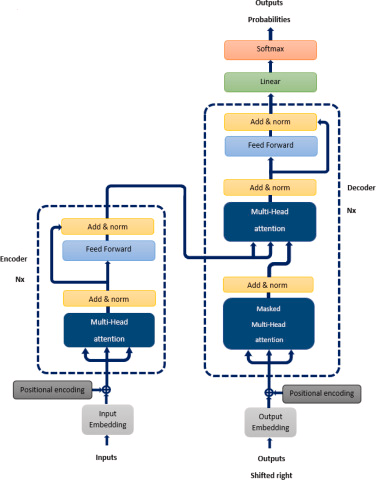 <br>
- Transformer 구조 : 기존 모델과의 차이는 **인코더와 디코더 내부를 무엇으로 채워 구조를 만들었는가** <br>



|  | Seq2Seq + Attention | Transformer |
|---|---|---|
| 인코더 디코더 내부 | LSTM | self attention|
| 어텐션 역할 | RNN 보조 역할 | 경제학 |
| 어텐션 사용 위치 | 디코더 -> 인코더 | 인코더 내부, 디코더 내부, 디코더 사이 |
| 단어 순서 정보 | RNN이 순서대로 읽으며 | positioning encoding으로 |
| 병렬 처리 |  x | o |

- 핵심 기술 
     - self attention : 문장 안 단어들이 서로를 참고해서 얼마나 중요한 관계를 맺고 있는지 한 번에 문맥 파악
     - multi head attention : 어텐션을 여러 갈래로 나눠서 다양한 관점에서 관계 파악
     - positioning encoding : 각 단어의 위치를 벡터로 만들어서 단어 벡터에 더함으로 사라진 순서 정보 보완

# 2. self attention
## 1. Query, key, value
### attention 기본 구조
- LSTM은 기억을 전달하는 방식 개선했으나 순서대로 처리하는 구조 자체를 바꾸진 못함
- 반면 Transformer는 구조 자체를 바꿔서 순서대로 전달하는 대신 모든 단어를 서로 직접 비교
     - 이때 쓰이는 재료 = Query, Key, Value

###  Q K V 의 개념
- attention은 Query 를 key들과 비교해서 관련도를 구하고, 그 비율만큼 value를 섞어서 결과를 만드는 계산이다. <br> 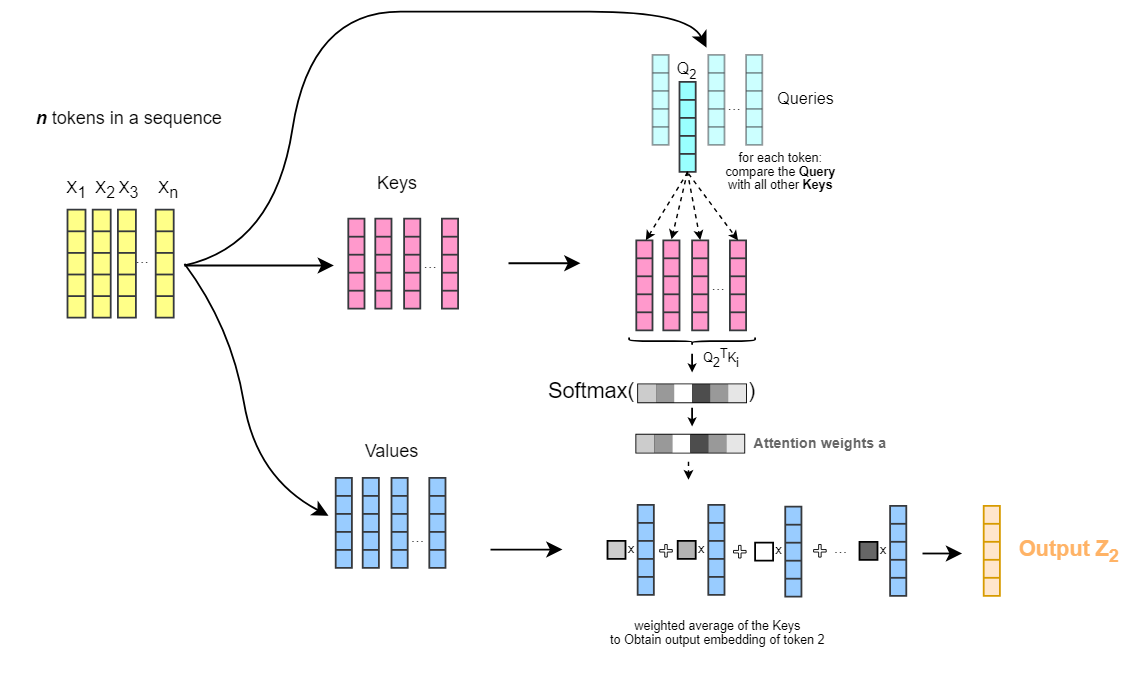 <br>
-  Query : 현재 처리 중인 단어가 다른 단어들에게 *'지금 나한테 필요한 정보가 무엇인지'* 묻는 벡터 
     - 도서관 -> 학생에 대해 알고 싶어 라는 궁금증
-  Key : 각 단어가 *나는 이런 정보를 갖고 있다* 고 보이는 벡터, Query와 비교해서 관련도 점수 결정
     - 학교 생활, 교육학개론, 요리 레시피 를 "학생"과 비교해서 점수 결정
- Value : 각 단어가 실제로 전달하는 정보 벡터, 관련도 비율만큼 모든 Value를 섞어서 최종 결과를 만든다.
- K와 V의 관계 : 하나의 단어에서 함께 만들어진 한 쌍 
     - Key : 찾을 때 기준, Value: 찾았을 때 가져오는 내용
     - Key - Value 나누는 이유 : 같은 단어라도 **무엇과 관련있는지 판단할 때 필요한 정보** 와 **실제로 전달해야할 정보**는 다를 수 있음

## 2. 기존 Cross Attention vs Self Attention
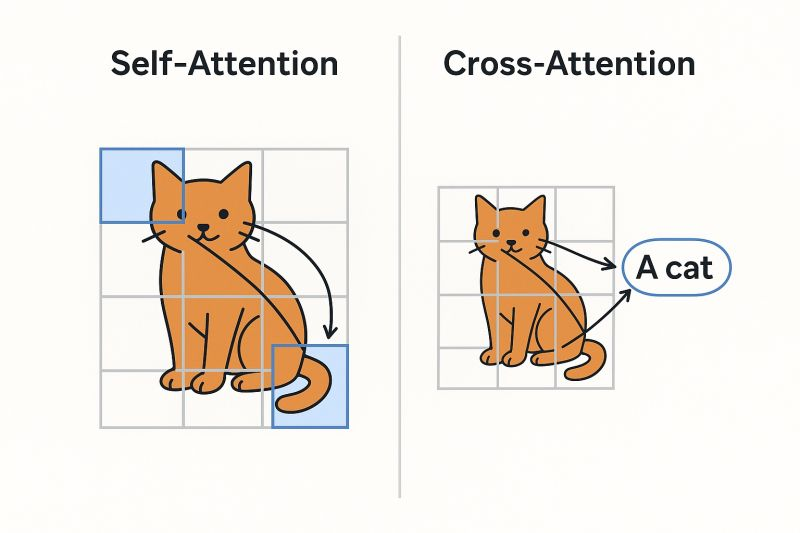 <br>
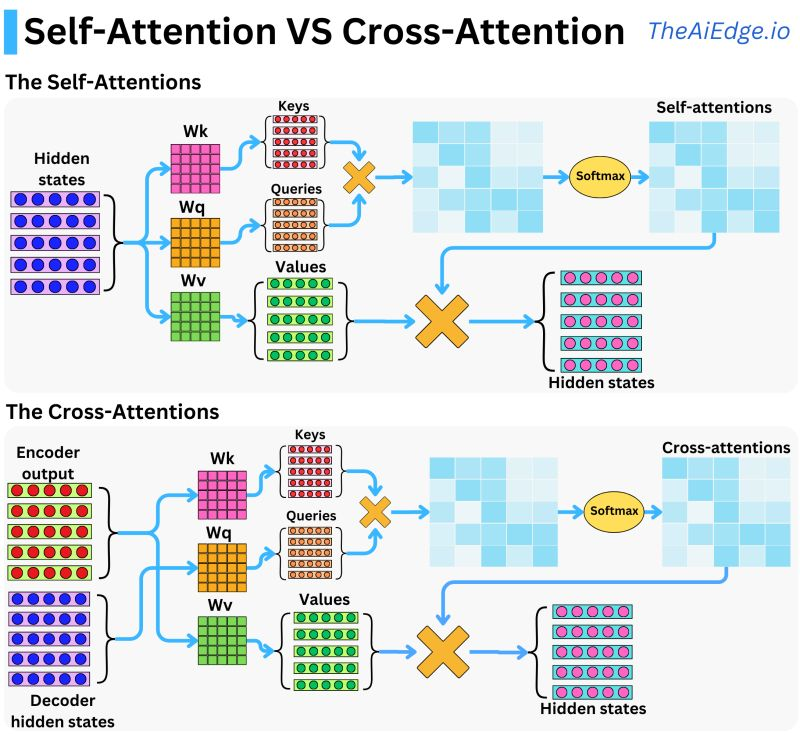<br> 
- 시퀀스 투 시퀀스의 어텐션은 디코더가 인코더를 참고하는 cross attention!
- transformer는 문장이 자기 자신을 참고하는 **self attention**이 핵심이다!

### 기존 어텐션 in seq2seq ( cross attention )
- **Query와 key-value 쌍이 서로 다른 시퀀스에서 출력**
- cross attention은 하나의 시퀀스가 *독립된 다른 시퀀스를 참고해서* 정보를 만들어낸다. 디코더가 인고터에게 *지금 어디를 봐야하지?*라고 묻는 구조
- 예시 : the cat is sleeping => 고양이가 ____ 
     - 1. Query 만들기 : 디코더가 '고양이가'를 바탕으로 Q 만든다 => 다음 단어를 위해 어떤 단어를 볼까?
     - 2. K, V 불러오기 : 인코더가 원문의 각 단어에 대해 만들어 둔 벡터를 (the cat is sleeping) k v로 사용
     - 3. attention score - 유사도 계산
     - 4. weighted sum - 비율만큼 value를 섞어 context vector 생성 => 디코더의 자기 정보와 컨텍스트 벡터로 "자고" 출력
     - = 오픈북 시험
- pitfall : 인코더와 디코더가 RNN 위에서 작동하기 때문에 *원문 내부 관계는 RNN 이 순서대로 읽으며 간접적으로 파악하고, 병렬 처리가 불가하다.*

### Self attention
- **Query 와 key - value 쌍이 같은 시퀀스에서 출력**
- 문장 스스로가 *우리끼리 누가 누구와 관련이 있지?* 를 묻는 구조
- 예시 : 가을 은행 냄새 지독해 중 "은행"
     - 1. 벡터 임베딩 Q K V
     - 2. 내적 및 관련도 점수 : "은행" Q와 모든 단어의 key 비교해서 관계 점수 계산
     - 3. 중요도 배분 
     - 4. 새로운 벡터 생성 -> 가을에 냄새 나는 열매 라는 의미를 담은 새 백터 생성
     - => 각자 문맥이 반영된 새 백터를 얻는다 : **병렬 처리 가능**

- 정리 : Transformer은 두 방식을 모두 사용!
     - 인코더 : self attention : 원문 단어끼리 관계 파악
     - 디코더 : self attention : 번역 중인 문장끼리 관계 파악
     - 인코더 - 디코더 사이 : cross attention : 번역하면서 원문 참고
     - *RNN이 하던 문장 내부 이해* = **self attention**, *attention이 하던 원문 참고*=**cross attention**

## 3. scaled dot product attention

### dot product attention
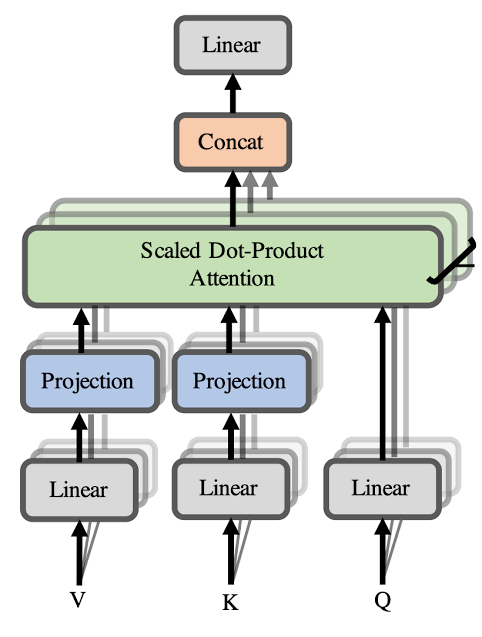 <br>
- attention은 Q 와 K를 비교해 관련도를 구한다 => 여기서 *비교*는 **scaled dot product attention**으로
- attention score 계산하는 가장 기본적 방법 중 하나
     - Q와 K 벡터를 내적해서 관련도 점수를 구한다. = '얼마나 닮았는지' 숫자로 표현
- 기본적 과정 <br> 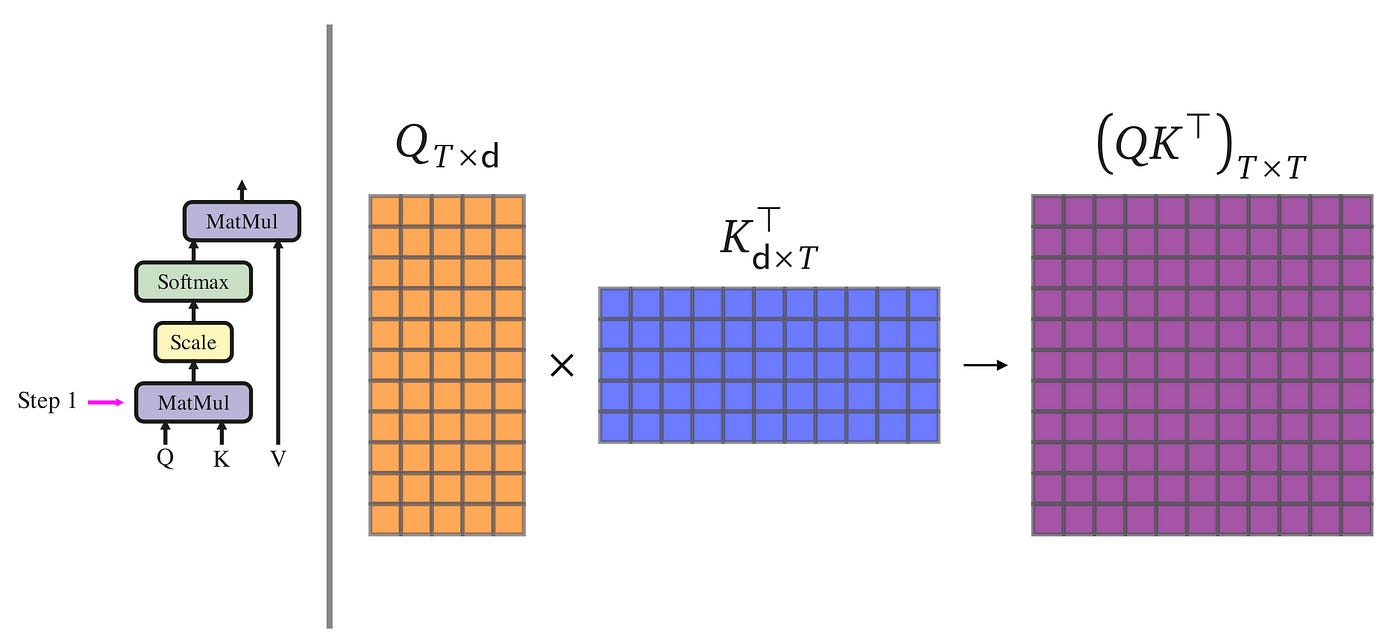 <br>
     - 1. attention score 계산 : Q와 전치한 K를 곱한다 = 모든단어x모든단어의 관련도 점수표
          - 행렬 곱셈으로 모든 점수 동시에 계산 **병렬처리구현**
          - 가로 = 질문하는 단어, 세로 = 참고대상단어
     - 2. 계산하는 값에 softmax 적용 -> attention weight 산출
          - 이 단어는 다른 단어들을 몇 퍼센트씩 참고하는가
     - 3. 최종 결과값 : attention weight x value 
- 문제점 : attention score의 극단화 
     - 벡터 차원이 커질수록 내적이 지나치게 커질 수 있다. -> 특정 단어에 확률이 과도하게 몰리는 현상
     - 이로 인해 기울기가 0에 가까워져 학습이 안되는 기울기 소실 문제 발생 가능

### Scaled Dot-Product Attention
- **transformer의 attention 계산 공식 그 자체!** 
- 기존의 dot product attention 문제를 해결한 방법 => 내적과 소프트맥스 사이에 *스케일링 단계 하나 추가*
- Scaled Dot-Product Attention로 얻어지는 벡터
     - cross attention : context vector - 현재 생성 중인 단어에 필요한 원문 정보를 '비율만큼 모은 벡터'
     - self attention : 문장 내 다른 단어들과의 관계가 반영이 되어서 *의미가 업데이트가 된 단어 벡터*


# 3. Multi Head attention
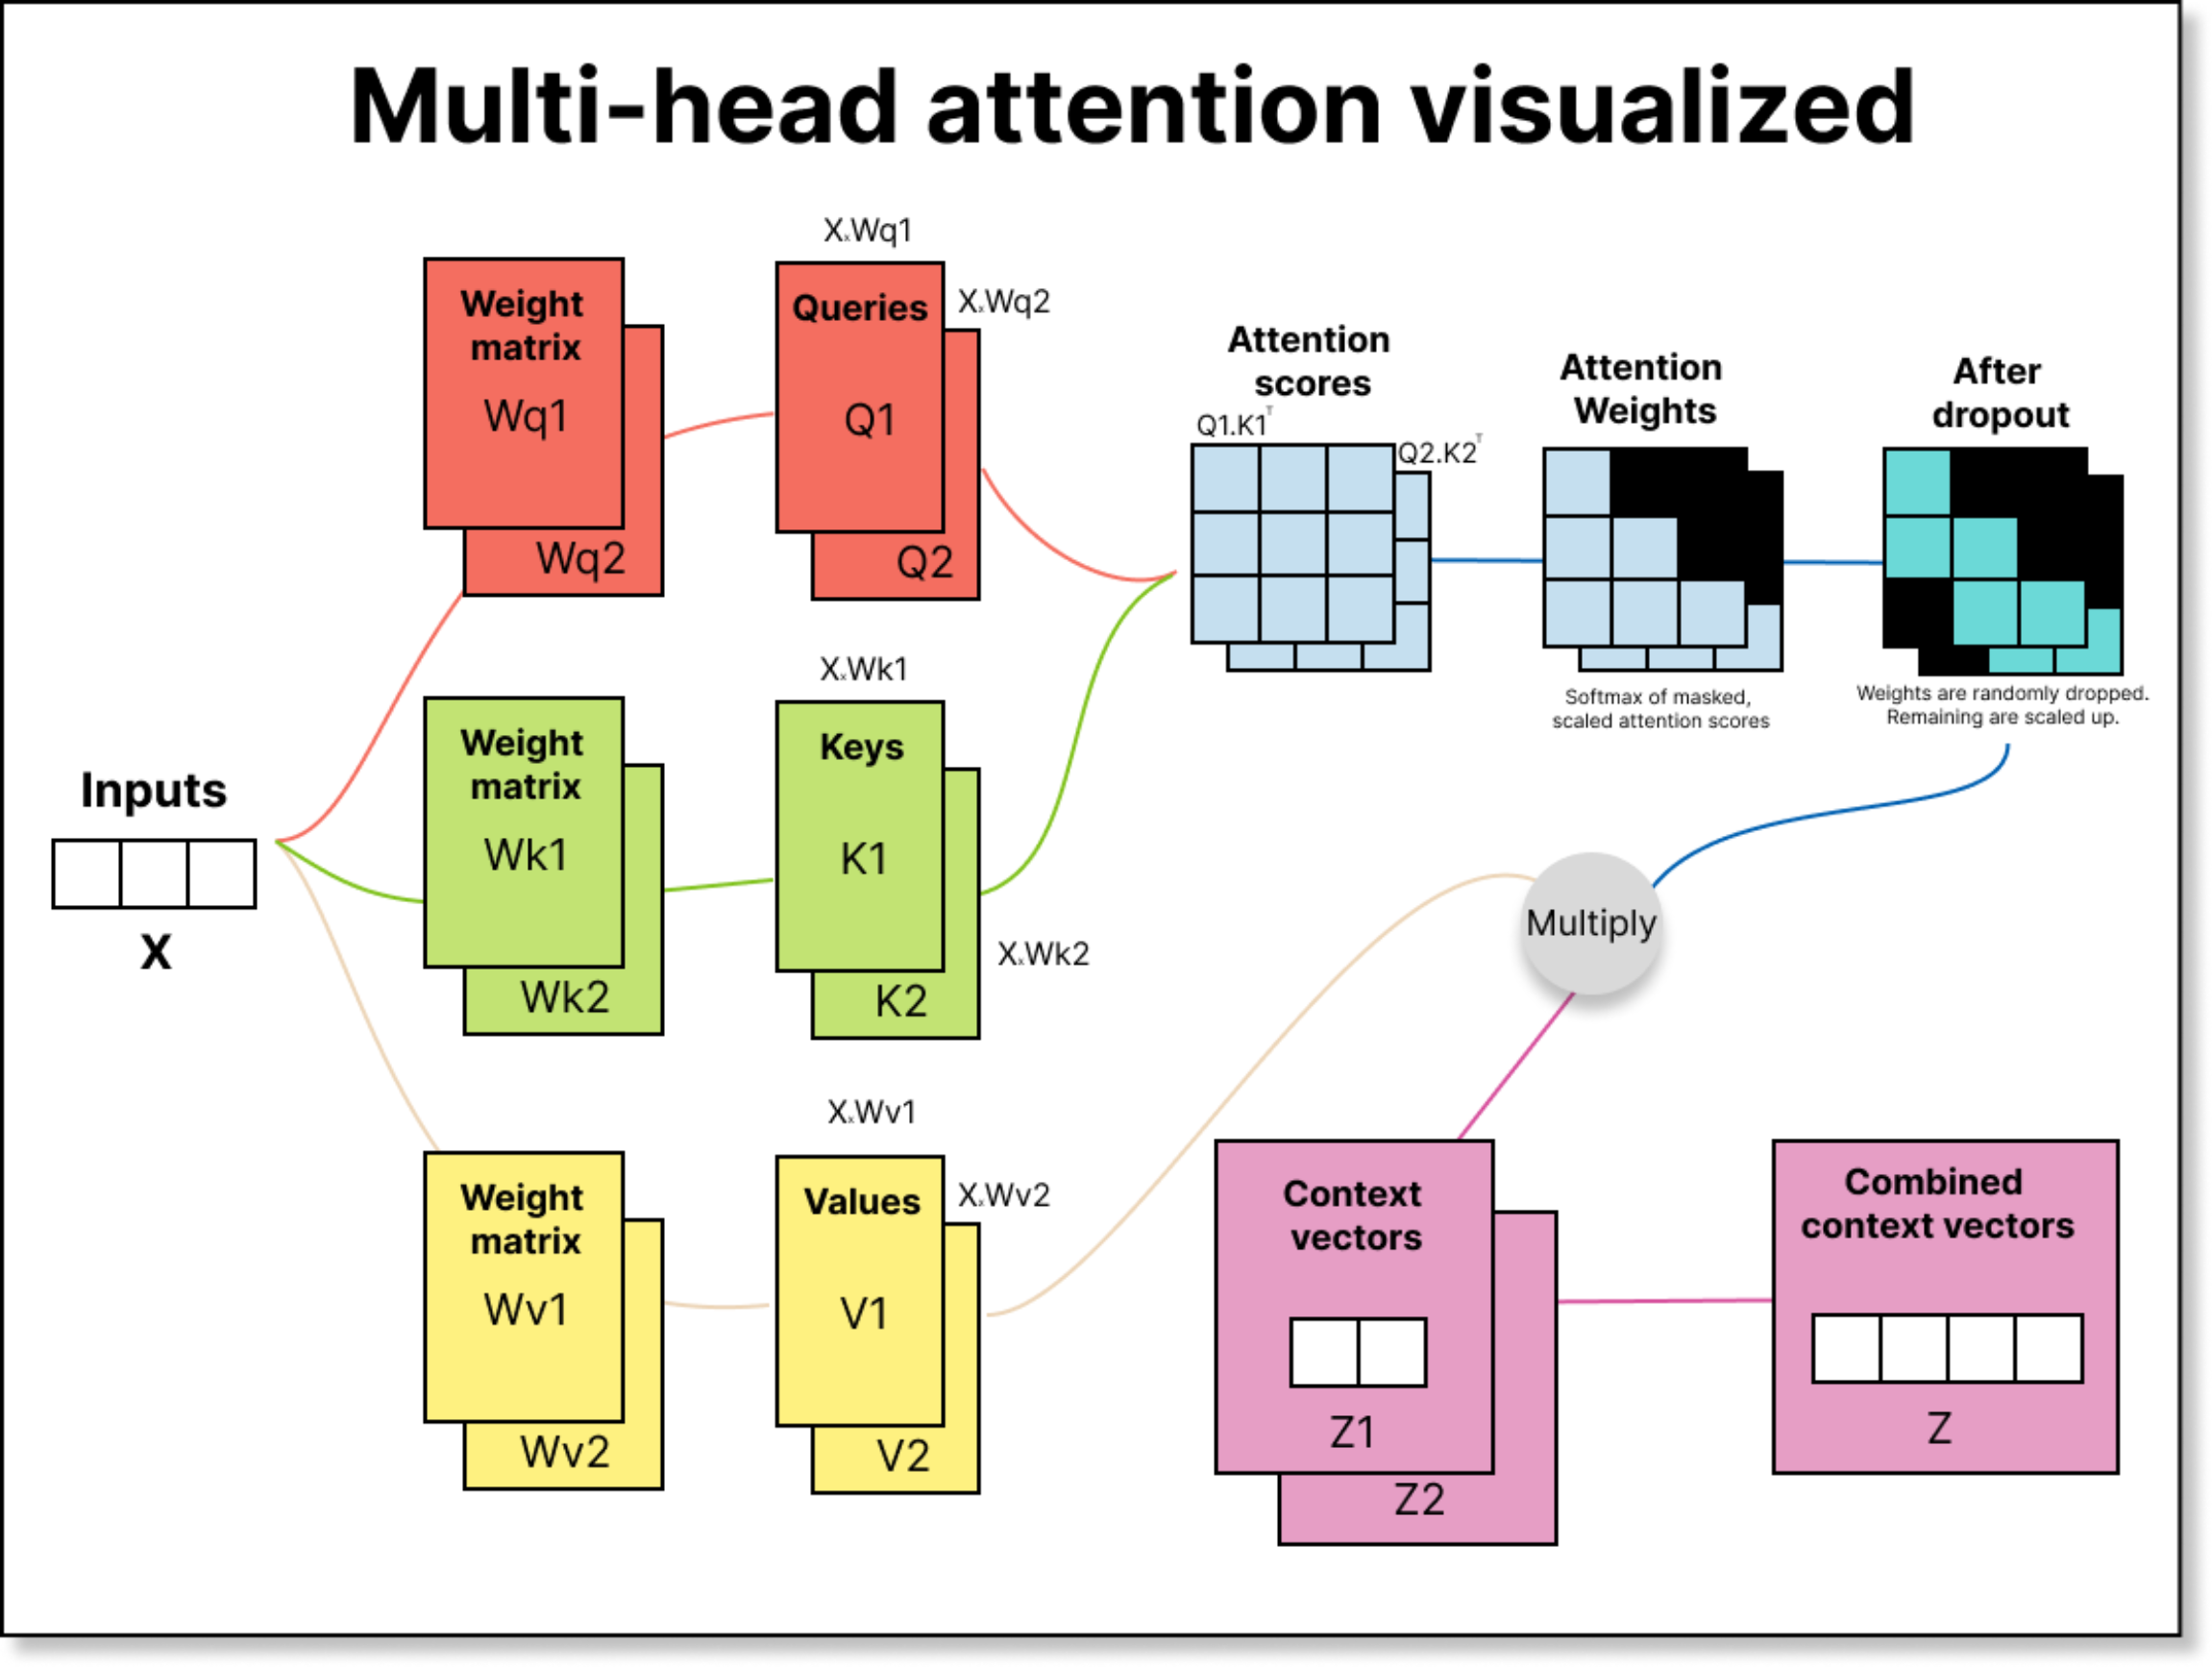
## 1. 왜 multi head attention을 사용할까?

### Single-Head Attention VS. Multi-Head Attention
- head란? attention 계산을 한 번 하는 독립된 단위 
     - 헤드마다 가중치 행렬 숫자가 다르기 때문에 같은 문장을 봐도 *집중하는 단어*가 달라진다.
- *single head attention* = 헤드가 하나
     - 가중치 행렬 세트 하나, 512차원 벡터를 그대로 한 번 어텐션한다 => 단어마다 가중치 분포가 하나 나옴
     - 한계 : 집중렬 100프로를 혼자 나눠 쓴다. -> 헤드가 하나면 100프로를 나눠줄 수 밖에 없어서 결과는 여러 정보가 섞인 *흐릿해진 벡터*
- *multi head attention* = attention을 쪼개서 여러 번 동시에 진행
     - 헤드마다 각자 100퍼센트! -> 헤드마다 질문 하나에 집중, 결과를 이어붙임 => 정보가 섞이지 않고 또렷하게 남는다.

## 2. multi head attention 작동 방식
<I love you>에서 love가 multi head attention 을 통과하는 과정

1. 분할 = 각 단어의 8개의 관점 만들기 (Q K V 8세트)
2. 병렬 어텐션 계산 , 각 헤드별 각자 분석 
     - 헤드가 서로 간섭하지 않고 동시에 Scaled Dot-Product Attention 계산
     - 헤드 1 안에서는 ...
          - 1. 점수 매기기 (love Q와 단어들의 K와 내적 > 관련도 점수)
          - 2. 크기 조절 (계산된 점수를 각 헤드 차원의 제곱근(루트64=8)로 나눠줌)
          - 3. 가중치 변환 (softmax)
          - 4. 섞기 (가중치대로 I, love, you의 V 에 곱해서 모두 더하면 head 1의 결과)
          - => head 2~8도 각자의 Q V K 로 같은 계산을 동시에, 독립적으로
3. 이어붙이기 : 8개의 64차원 결과를 순서대로 한 줄로
4. 섞기 : 8개의 관점을 하나의 의미로 융합
5. love에 대한  multi head attention 레이어의 최종 출력 벡터 얻게 됨.

# 4. Transformer 전체 아키텍처
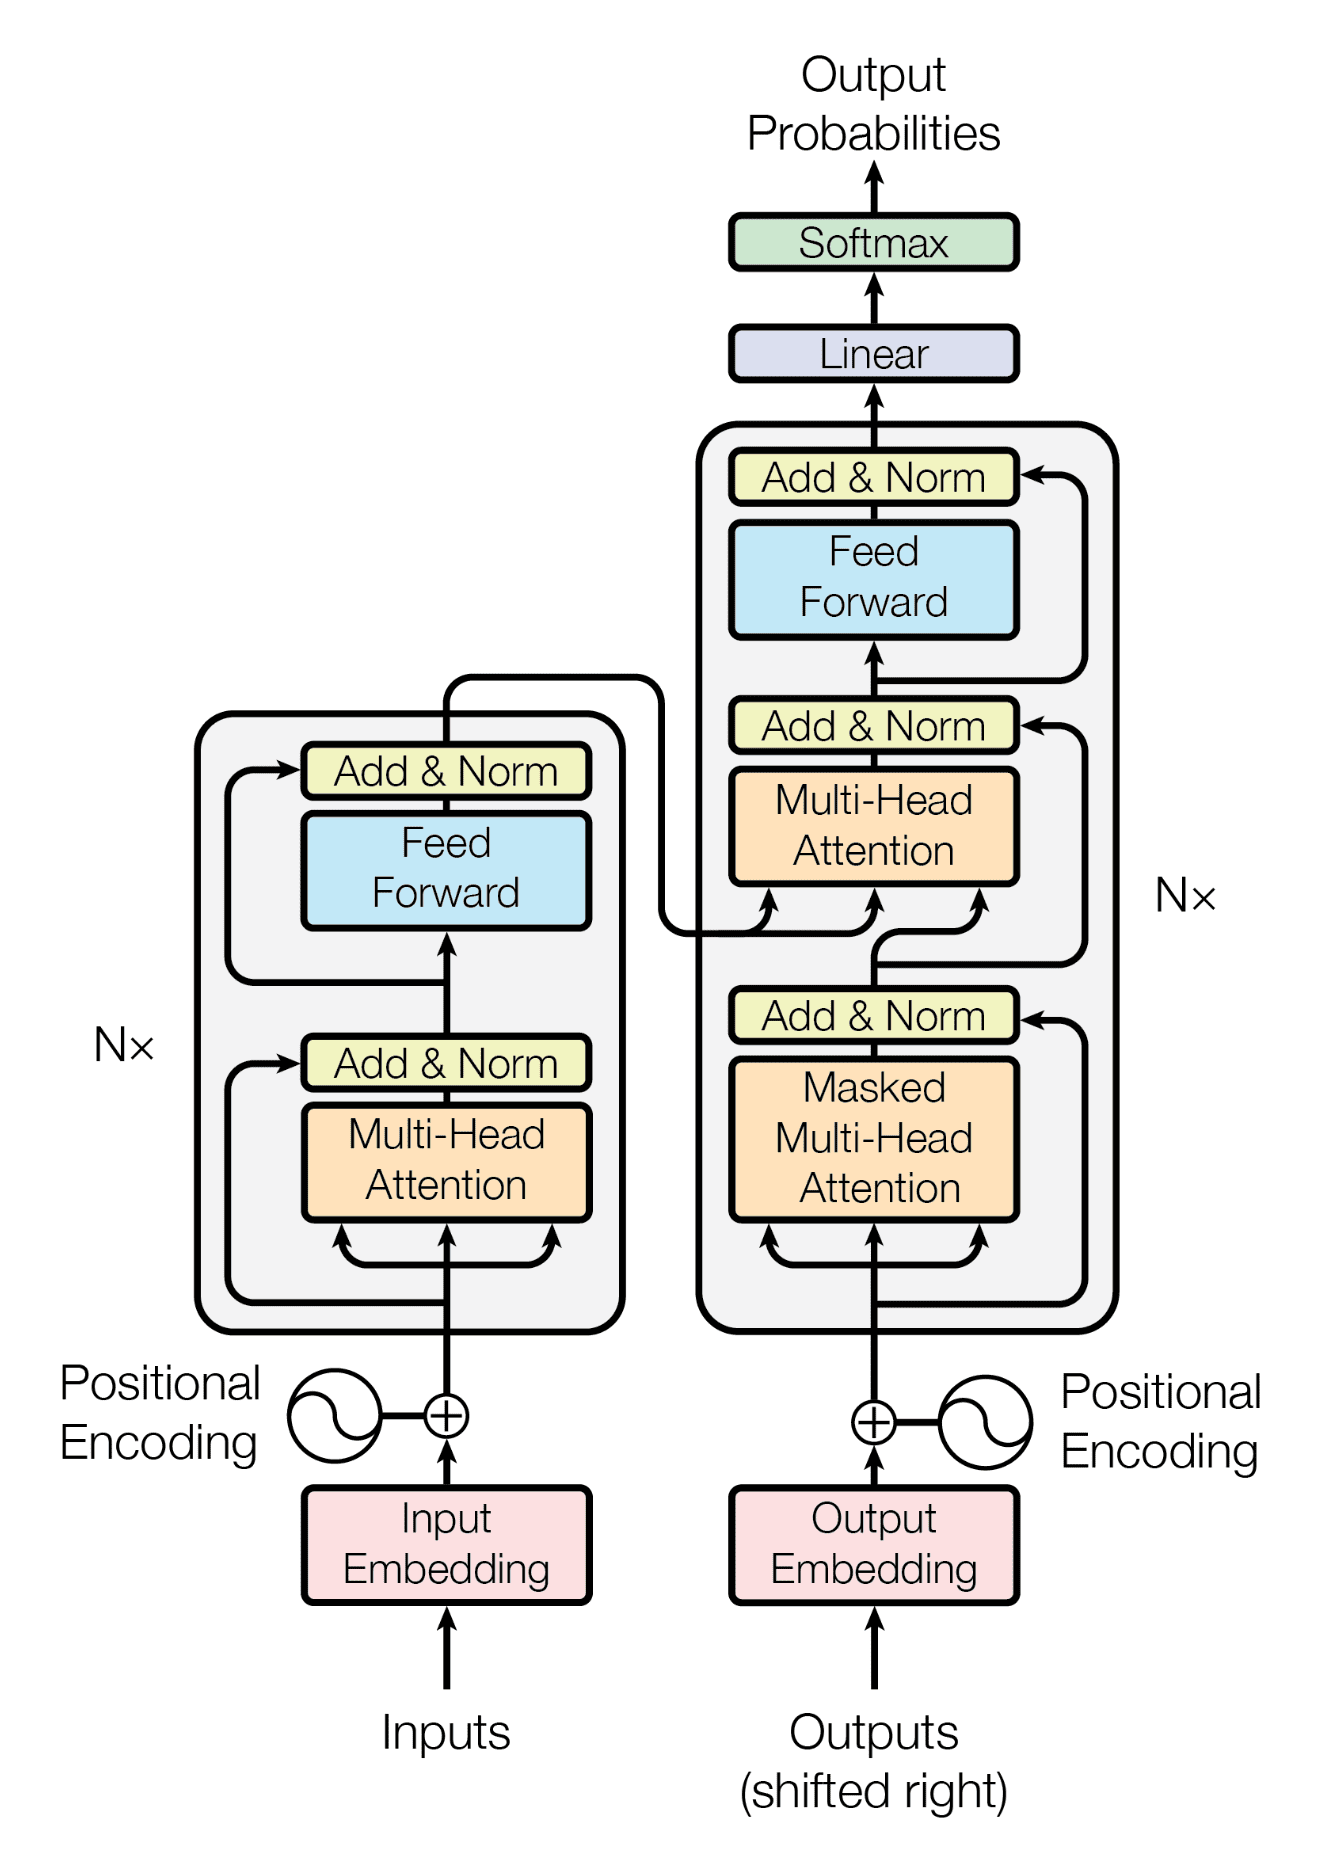 <br>

## 1. 트랜스포머의 전처리 단계
### (1) 토큰화 : 문장을 조각내기
- 문장을 모델이 다루는 기본 단위 (토큰)으로 자르는 것
### (2) 임베딩 : 단어에 좌표 주기
- 각 토큰을 숫자(벡터)로 바꾸는 것을 의미
- 벡터의 길이 = 벡터의 차원
- 임베딩의 핵심 원리 = 단어 -> 공간적 의미, 뜻이 비슷하면 가까운 좌표 <br>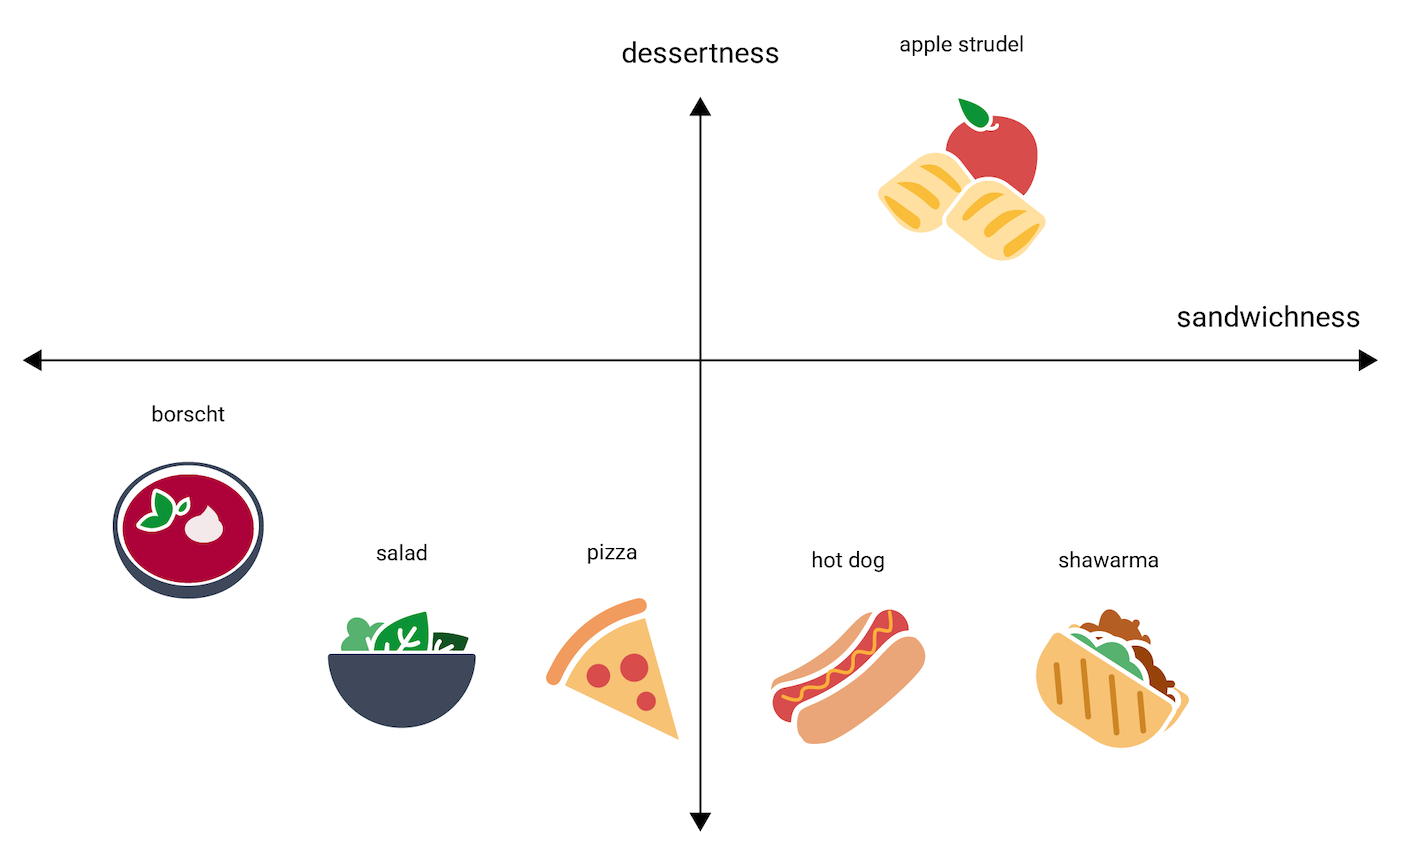

### (3) positioning encoding : 순서 번호표 붙이기
- 순서 정보를 임베딩 벡터에 추가하는 단계 => 같은 단어여도 자리가 다르면 최종벡터가 다르다
- transformer는 모든 단어를 한번에 보기에! 

## 2. 트랜스포머의 encoder 와 decoder
### encoder : 원문을 깊이 이해하는 분석팀
- encoder 한 층 = 'multi head attention'(원문 단어끼리 서로를 보며 문맥 파악) + 'feed forward network' (단어 하나하나를 따로 더 깊이 가공, 단어마다 따로/ 같은 가중치로 적용)

- add & norm :모든 부품에 붙는 안전장치
     - add : residual connection (잔차연결) -> 부품을 통과한 결과에 *원래 입력을 그대로 더해준다.*
     - norm : layer normalization (층 정규화) -> 한 벡터 안의 숫자를 평균 0, 분산 1로 맞춰줌 
### decoder : 변역문을 한 단어씩 쓰는 작성팀
- decoder 한 층 = 'masked multi head self attention'(지금까지 쓴 단어끼리의 관계 파악) + 'encoder-decoder attention'(원문 분석 자료에서 필요한 부분 찾기) + 'feed forward network'
     - 세 부품 뒤에도 add & norm이 붙는다.
     - 다 통과하면 linear + softmax가 다음 단어의 확률 계산
- masked multi head self attention :미래 시점 단어 정보 가리고 자기보다 앞의 단어만 보게하는 매커니즘 (컨닝방지!)
- encoder-decoder attention : 출력 문장과 입력 문장을 연결하는 과정


## 3. 전체 모델 및 데이터 흐름
- 입력 준비 : 문장을 의미+위치 벡터로 바꾸기
     - 임베딩
     - positional encoding
- 인코더 : 입력 문장의 *문맥적 의미* 깊이 이해하기
- 디코더 : 번역 문장을 *한 단어씩* 생성하기